In [1]:
import pandas as pd
from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import RandomizedSearchCV, LeaveOneGroupOut, cross_val_score

# Mount Google Drive
drive.mount('/content/drive')

# Define the path to the dataset
dataset_path = '/content/drive/MyDrive/Colab/windowed.csv'

# Load the dataset
try:
    df = pd.read_csv(dataset_path)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print(f"Error: The file '{dataset_path}' was not found.")
    df = None

if df is not None:
    # Display basic information
    print("\nFirst 5 rows of the dataset:")
    display(df.head())

    # Assign the loaded DataFrame to windowed_df
    windowed_df = df.copy()

    # Assuming 'class' is target and 'user' is the grouping column
    if 'class' in windowed_df.columns and 'user' in windowed_df.columns:
        # Renamed X variable to reflect it is windowed data (not discretized)
        X_windowed = windowed_df.drop(columns=['class', 'user'])
        y_windowed = windowed_df['class']
        print("\nFeatures (X_windowed) and target (y_windowed) defined.")
    else:
        print("Error: 'class' or 'user' column not found.")
        X_windowed = None
        y_windowed = None

Mounted at /content/drive
Dataset loaded successfully.

First 5 rows of the dataset:


,x1_mean,x1_std,x1_min,x1_max,y1_mean,y1_std,y1_min,y1_max,z1_mean,z1_std,...,yaw3_mean,yaw3_std,yaw3_min,yaw3_max,yaw4_mean,yaw4_std,yaw4_min,yaw4_max,class,user
0,-1.500,1.309307,-3,1,95.875,2.356602,92,100,-61.625,2.133910,...,95.890168,3.504175,87.247515,97.666804,-145.572439,0.297061,-146.051457,-145.085476,sitting,debora
1,0.000,1.309307,-1,3,97.250,1.488048,95,100,-61.000,1.414214,...,96.897433,0.297046,96.519802,97.125016,-145.351133,0.278429,-145.877193,-145.085476,sitting,debora
2,0.125,0.991031,-1,2,97.125,1.457738,95,99,-61.375,1.060660,...,97.033040,0.370894,96.519802,97.666804,-144.804852,0.621709,-145.523912,-143.901716,sitting,debora
3,-0.625,2.503569,-4,3,97.500,1.927248,95,100,-62.125,0.834523,...,97.168019,0.367925,96.519802,97.666804,-146.437571,3.140239,-150.780753,-142.883139,sitting,debora
4,-1.625,1.846812,-4,1,98.875,1.457738,96,100,-65.000,1.603567,...,97.101559,0.448704,96.519802,97.740341,-152.642844,1.675857,-154.019579,-150.018361,sitting,debora



Features (X_windowed) and target (y_windowed) defined.


### RANDOM FOREST

In [2]:

# Proceed with Nested LOSO Cross-Validation
if df is not None and X_windowed is not None and y_windowed is not None:
    print("Starting Nested LOSO Cross-Validation with Randomized Search...")

    # Expanded hyperparameter space
    param_dist_rf = {
        'n_estimators': [100, 200, 300, 500],
        'max_depth': [None, 10, 20, 30, 50],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2'],
        'bootstrap': [True, False]
    }

    # Initialize RandomForestClassifier
    rf_classifier = RandomForestClassifier(random_state=42)

    # Configure Inner Randomized Search
    # n_iter=10 limits the search to 10 random combinations per fold
    inner_cv = 3
    random_search_rf = RandomizedSearchCV(
        estimator=rf_classifier,
        param_distributions=param_dist_rf,
        n_iter=10,
        cv=inner_cv,
        scoring='f1_weighted',
        n_jobs=-1,
        verbose=0,
        random_state=42
    )

    # Configure Outer Leave-One-Subject-Out (LOSO)
    loso = LeaveOneGroupOut()

    # Perform nested cross-validation
    print("Performing nested LOSO CV...")
    nested_f1_scores_rf = cross_val_score(
        random_search_rf,
        X_windowed,
        y_windowed,
        groups=windowed_df['user'],
        cv=loso,
        scoring='f1_weighted',
        n_jobs=-1
    )

    print("\n--- Nested LOSO Cross-Validation Results (Tuned Random Forest) ---")
    print("F1-scores from each outer LOSO fold:")
    for i, score in enumerate(nested_f1_scores_rf):
        print(f"  Fold {i+1}: {score:.4f}")

    overall_f1_tuned_rf = np.mean(nested_f1_scores_rf)
    print(f"\nOverall Mean F1-score: {overall_f1_tuned_rf:.4f}")
else:
    print("Skipping cross-validation due to missing data.")

Starting Nested LOSO Cross-Validation with Randomized Search...
Performing nested LOSO CV...

--- Nested LOSO Cross-Validation Results (Tuned Random Forest) ---
F1-scores from each outer LOSO fold:
  Fold 1: 0.8872
  Fold 2: 0.9170
  Fold 3: 0.6877
  Fold 4: 0.8705

Overall Mean F1-score: 0.8406


### DECISION TREE

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV, LeaveOneGroupOut, cross_val_score
import numpy as np

# Proceed with Nested LOSO Cross-Validation
if df is not None and X_windowed is not None and y_windowed is not None:
    print("Starting Nested LOSO Cross-Validation with Decision Tree...")

    # Iperparametri specifici per Decision Tree
    param_dist_dt = {
        'criterion': ['gini', 'entropy'],
        'max_depth': [None, 5, 10, 20, 30],
        'min_samples_split': [2, 5, 10, 20],
        'min_samples_leaf': [1, 2, 4, 8],
        'max_features': [None, 'sqrt', 'log2']
    }

    # Inizializza DecisionTreeClassifier
    dt_classifier = DecisionTreeClassifier(random_state=42)

    # Configure Inner Randomized Search
    # n_iter=5 limita la ricerca a 5 combinazioni casuali per ogni fold
    inner_cv = 3
    random_search_dt = RandomizedSearchCV(
        estimator=dt_classifier,
        param_distributions=param_dist_dt,
        n_iter=5, # Ridotto a 5 combinazioni
        cv=inner_cv,
        scoring='f1_weighted',
        n_jobs=-1,
        verbose=0,
        random_state=42
    )

    # Configure Outer Leave-One-Subject-Out (LOSO)
    loso = LeaveOneGroupOut()

    # Perform nested cross-validation
    print("Performing nested LOSO CV (Decision Tree)...")
    nested_f1_scores_dt = cross_val_score(
        random_search_dt,
        X_windowed,
        y_windowed,
        groups=windowed_df['user'],
        cv=loso,
        scoring='f1_weighted',
        n_jobs=-1
    )

    print("\n--- Nested LOSO Cross-Validation Results (Tuned Decision Tree) ---")
    print("F1-scores from each outer LOSO fold:")
    for i, score in enumerate(nested_f1_scores_dt):
        print(f"  Fold {i+1}: {score:.4f}")

    overall_f1_tuned_dt = np.mean(nested_f1_scores_dt)
    print(f"\nOverall Mean F1-score: {overall_f1_tuned_dt:.4f}")
else:
    print("Skipping cross-validation due to missing data.")

Starting Nested LOSO Cross-Validation with Decision Tree...
Performing nested LOSO CV (Decision Tree)...

--- Nested LOSO Cross-Validation Results (Tuned Decision Tree) ---
F1-scores from each outer LOSO fold:
  Fold 1: 0.8494
  Fold 2: 0.8039
  Fold 3: 0.6857
  Fold 4: 0.8473

Overall Mean F1-score: 0.7966


### ADABOOST

In [4]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, LeaveOneGroupOut, cross_val_score
import numpy as np

# Proceed with Nested LOSO Cross-Validation
if df is not None and X_windowed is not None and y_windowed is not None:
    print("Starting Nested LOSO Cross-Validation with AdaBoost...")

    # Hyperparameter space for AdaBoost
    # Note: By default, AdaBoost uses DecisionTreeClassifier(max_depth=1) as base estimator
    param_dist_ada = {
        'n_estimators': [50, 100, 200, 500],
        'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
        'algorithm': ['SAMME', 'SAMME.R']
    }

    # Initialize AdaBoostClassifier
    ada_classifier = AdaBoostClassifier(random_state=42)

    # Configure Inner Randomized Search
    # n_iter=5 limits the search to 5 random combinations per fold
    inner_cv = 3
    random_search_ada = RandomizedSearchCV(
        estimator=ada_classifier,
        param_distributions=param_dist_ada,
        n_iter=5, # Limited to 5 combinations as requested
        cv=inner_cv,
        scoring='f1_weighted',
        n_jobs=-1,
        verbose=0,
        random_state=42
    )

    # Configure Outer Leave-One-Subject-Out (LOSO)
    loso = LeaveOneGroupOut()

    # Perform nested cross-validation
    print("Performing nested LOSO CV (AdaBoost)...")
    nested_f1_scores_ada = cross_val_score(
        random_search_ada,
        X_windowed,
        y_windowed,
        groups=windowed_df['user'],
        cv=loso,
        scoring='f1_weighted',
        n_jobs=-1
    )

    print("\n--- Nested LOSO Cross-Validation Results (Tuned AdaBoost) ---")
    print("F1-scores from each outer LOSO fold:")
    for i, score in enumerate(nested_f1_scores_ada):
        print(f"  Fold {i+1}: {score:.4f}")

    overall_f1_tuned_ada = np.mean(nested_f1_scores_ada)
    print(f"\nOverall Mean F1-score: {overall_f1_tuned_ada:.4f}")
else:
    print("Skipping cross-validation due to missing data.")

Starting Nested LOSO Cross-Validation with AdaBoost...
Performing nested LOSO CV (AdaBoost)...

--- Nested LOSO Cross-Validation Results (Tuned AdaBoost) ---
F1-scores from each outer LOSO fold:
  Fold 1: 0.8381
  Fold 2: 0.7919
  Fold 3: 0.6699
  Fold 4: 0.8716

Overall Mean F1-score: 0.7929


### k-NN

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, cross_val_score
import numpy as np

# Inizializzazione della lista per memorizzare i punteggi F1
nested_f1_scores_knn = []

if X_windowed is not None and y_windowed is not None:
    print("Starting Nested LOSO Cross-Validation with Tuned KNeighborsClassifier...")

    # Definizione della griglia di parametri per KNN
    # Nota: usiamo il prefisso 'knn__' perché il classificatore è all'interno di una Pipeline
    param_grid_knn = {
        'knn__n_neighbors': [3, 5, 7, 9],
        'knn__weights': ['uniform', 'distance'],
        'knn__metric': ['euclidean', 'manhattan']
    }

    # Creazione della pipeline: Scaling (fondamentale per KNN) + Classificatore
    knn_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier())
    ])

    # Configurazione della Inner Cross-Validation per la ricerca degli iperparametri
    inner_cv = 3
    grid_search_knn = GridSearchCV(
        estimator=knn_pipeline,
        param_grid=param_grid_knn,
        cv=inner_cv,
        scoring='f1_weighted',
        n_jobs=-1
    )

    # Configurazione della Outer Leave-One-Subject-Out (LOSO)
    loso = LeaveOneGroupOut()

    # Esecuzione della Nested Cross-Validation
    print("Performing nested LOSO CV for KNN...")
    nested_f1_scores_knn = cross_val_score(
        grid_search_knn,
        X_windowed,        # Variabile rinominata (rimosso 'discretized')
        y_windowed,
        groups=windowed_df['user'],
        cv=loso,
        scoring='f1_weighted',
        n_jobs=-1
    )

    print("\n--- Nested LOSO Cross-Validation Results (Tuned KNeighborsClassifier) ---")
    print("F1-scores from each outer LOSO fold:")
    for i, score in enumerate(nested_f1_scores_knn):
        print(f"  Fold {i+1}: {score:.4f}")

    overall_f1_tuned_knn = np.mean(nested_f1_scores_knn)
    print(f"\nOverall Mean F1-score across all nested LOSO folds (Tuned KNN): {overall_f1_tuned_knn:.4f}")
else:
    print("Skipping KNN cross-validation due to missing data.")

Starting Nested LOSO Cross-Validation with Tuned KNeighborsClassifier...
Performing nested LOSO CV for KNN...

--- Nested LOSO Cross-Validation Results (Tuned KNeighborsClassifier) ---
F1-scores from each outer LOSO fold:
  Fold 1: 0.4789
  Fold 2: 0.6451
  Fold 3: 0.4667
  Fold 4: 0.8565

Overall Mean F1-score across all nested LOSO folds (Tuned KNN): 0.6118


### NAIVE BAYESIAN

In [9]:
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, LeaveOneGroupOut, cross_val_score
import numpy as np

# Proceed with Nested LOSO Cross-Validation
if df is not None and X_windowed is not None and y_windowed is not None:
    print("Starting Nested LOSO Cross-Validation with Gaussian Naive Bayes...")

    # Define a Pipeline: 1. Scale data, 2. Run GaussianNB
    # Scaling is optional for NB but good for numerical stability
    nb_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('nb', GaussianNB())
    ])

    # Hyperparameter space for GaussianNB
    # var_smoothing is the primary hyperparameter to tune for GaussianNB.
    # It accounts for the portion of the largest variance of all features
    # to be added to variances for calculation stability.
    param_dist_nb = {
        'nb__var_smoothing': np.logspace(0, -9, num=100)
    }

    # Configure Inner Randomized Search
    # n_iter=5 limits the search to 5 random combinations per fold
    inner_cv = 3
    random_search_nb = RandomizedSearchCV(
        estimator=nb_pipeline,
        param_distributions=param_dist_nb,
        n_iter=5,
        cv=inner_cv,
        scoring='f1_weighted',
        n_jobs=-1,
        verbose=0,
        random_state=42
    )

    # Configure Outer Leave-One-Subject-Out (LOSO)
    loso = LeaveOneGroupOut()

    # Perform nested cross-validation
    print("Performing nested LOSO CV (Naive Bayes)...")
    nested_f1_scores_nb = cross_val_score(
        random_search_nb,
        X_windowed,
        y_windowed,
        groups=windowed_df['user'],
        cv=loso,
        scoring='f1_weighted',
        n_jobs=-1
    )

    print("\n--- Nested LOSO Cross-Validation Results (Tuned Gaussian NB) ---")
    print("F1-scores from each outer LOSO fold:")
    for i, score in enumerate(nested_f1_scores_nb):
        print(f"  Fold {i+1}: {score:.4f}")

    overall_f1_tuned_nb = np.mean(nested_f1_scores_nb)
    print(f"\nOverall Mean F1-score: {overall_f1_tuned_nb:.4f}")
else:
    print("Skipping cross-validation due to missing data.")

Starting Nested LOSO Cross-Validation with Gaussian Naive Bayes...
Performing nested LOSO CV (Naive Bayes)...

--- Nested LOSO Cross-Validation Results (Tuned Gaussian NB) ---
F1-scores from each outer LOSO fold:
  Fold 1: 0.5789
  Fold 2: 0.8227
  Fold 3: 0.4226
  Fold 4: 0.8165

Overall Mean F1-score: 0.6602


### BOX PLOT COMPARISON

/tmp/ipykernel_33239/3753361252.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='Model', y='F1-score', data=df_melted, palette='Set2', width=0.5)


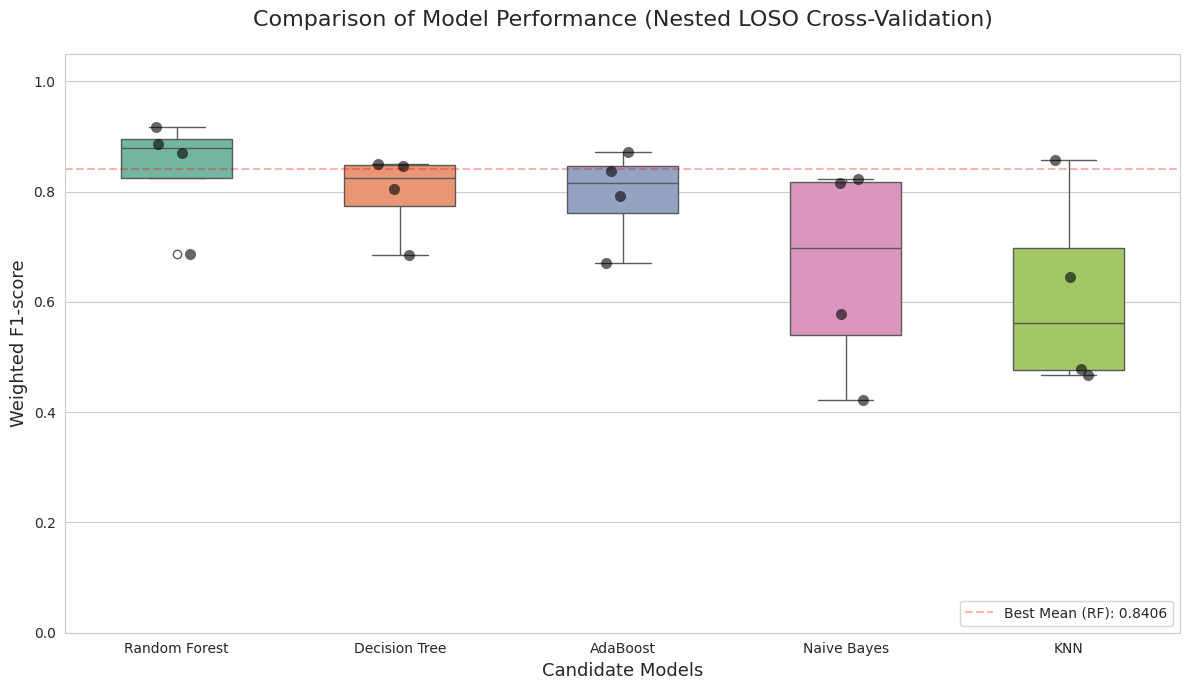

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Prepare the data from your results
results_data = {
    'Random Forest': [0.8872, 0.9170, 0.6877, 0.8705],
    'Decision Tree': [0.8494, 0.8039, 0.6857, 0.8473],
    'AdaBoost': [0.8381, 0.7919, 0.6699, 0.8716],
    'Naive Bayes': [0.5789, 0.8227, 0.4226, 0.8165],
    'KNN': [0.4789, 0.6451, 0.4667, 0.8565]
}

# 2. Convert to a DataFrame and reshape it for Seaborn (melt)
df_results = pd.DataFrame(results_data)
df_melted = df_results.melt(var_name='Model', value_name='F1-score')

# 3. Create the plot
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Create the boxplot
# palette='Set2' provides a clean, academic look
ax = sns.boxplot(x='Model', y='F1-score', data=df_melted, palette='Set2', width=0.5)

# Overlay individual fold points (Stripplot)
# This is crucial for small samples to show the actual distribution of the 4 users
sns.stripplot(x='Model', y='F1-score', data=df_melted,
              color='black', alpha=0.6, size=8, jitter=True)

# 4. Add labels and formatting
plt.title('Comparison of Model Performance (Nested LOSO Cross-Validation)', fontsize=16, pad=20)
plt.ylabel('Weighted F1-score', fontsize=13)
plt.xlabel('Candidate Models', fontsize=13)
plt.ylim(0, 1.05)  # Set Y axis from 0 to 1 with a little padding

# Add horizontal dashed line for the best mean score reference (Random Forest)
mean_rf = np.mean(results_data['Random Forest'])
plt.axhline(mean_rf, color='red', linestyle='--', alpha=0.3, label=f'Best Mean (RF): {mean_rf:.4f}')

plt.legend(loc='lower right')
plt.tight_layout()

# Show the plot
plt.show()

### STATISTICAL TEST: WILCOXON

In [12]:
from scipy.stats import wilcoxon
import pandas as pd

# 1. Define the scores for each model
scores = {
    'Random Forest': [0.8872, 0.9170, 0.6877, 0.8705],
    'Decision Tree': [0.8494, 0.8039, 0.6857, 0.8473],
    'AdaBoost': [0.8381, 0.7919, 0.6699, 0.8716],
    'Naive Bayes': [0.5789, 0.8227, 0.4226, 0.8165],
    'KNN': [0.4789, 0.6451, 0.4667, 0.8565]
}

best_model_name = 'Random Forest'
best_model_scores = scores[best_model_name]

print(f"--- Wilcoxon Signed-Rank Test Results ---")
print(f"Comparing all models against the best model: {best_model_name}\n")

comparison_results = []

for model_name, model_scores in scores.items():
    if model_name == best_model_name:
        continue

    # Perform Wilcoxon Signed-Rank Test (paired)
    # Using alternative='greater' tests if Random Forest is significantly better
    stat, p_value = wilcoxon(best_model_scores, model_scores)

    comparison_results.append({
        'Comparison': f"{best_model_name} vs {model_name}",
        'Stat': stat,
        'p-value': p_value,
        'Significant (p < 0.05)': 'Yes' if p_value < 0.05 else 'No'
    })

# Display as a clean table
df_stat = pd.DataFrame(comparison_results)
print(df_stat.to_string(index=False))

print("\n--- Statistical Interpretation ---")
print("Note: With a sample size of n=4 (4 folds), the Wilcoxon test cannot reach")
print("a p-value below 0.05 even if one model wins in every fold.")
print("The results above indicate the trend, but higher fold counts (or more subjects)")
print("would be required to achieve formal statistical significance.")

--- Wilcoxon Signed-Rank Test Results ---
Comparing all models against the best model: Random Forest

                    Comparison  Stat  p-value Significant (p < 0.05)
Random Forest vs Decision Tree   0.0    0.125                     No
     Random Forest vs AdaBoost   1.0    0.250                     No
  Random Forest vs Naive Bayes   0.0    0.125                     No
          Random Forest vs KNN   0.0    0.125                     No

--- Statistical Interpretation ---
Note: With a sample size of n=4 (4 folds), the Wilcoxon test cannot reach
a p-value below 0.05 even if one model wins in every fold.
The results above indicate the trend, but higher fold counts (or more subjects)
would be required to achieve formal statistical significance.


/tmp/ipykernel_33239/1884128267.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Model', y='Probability', data=df_probs, palette=colors)


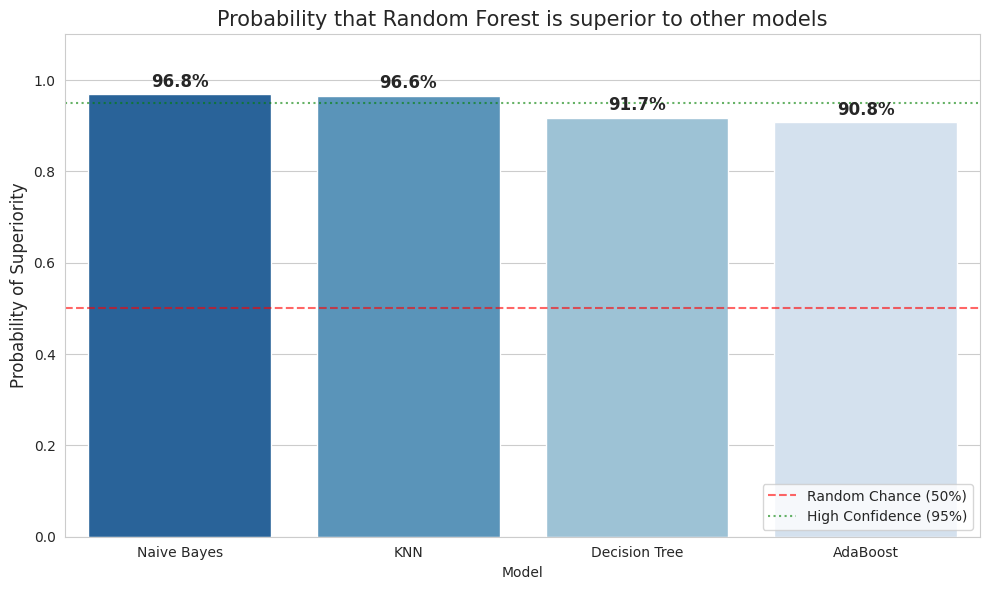

--- Probability of Superiority (compared to Random Forest) ---
There is a 96.84% probability that Random Forest outperforms Naive Bayes
There is a 96.60% probability that Random Forest outperforms KNN
There is a 91.70% probability that Random Forest outperforms Decision Tree
There is a 90.78% probability that Random Forest outperforms AdaBoost


In [13]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data from your results
scores = {
    'Random Forest': [0.8872, 0.9170, 0.6877, 0.8705],
    'Decision Tree': [0.8494, 0.8039, 0.6857, 0.8473],
    'AdaBoost': [0.8381, 0.7919, 0.6699, 0.8716],
    'Naive Bayes': [0.5789, 0.8227, 0.4226, 0.8165],
    'KNN': [0.4789, 0.6451, 0.4667, 0.8565]
}

def calculate_probability_superiority(best_scores, other_scores):
    """
    Calculates the probability that the best model is better than the other
    using a Bayesian-inspired approach (Student's t-distribution).
    """
    differences = np.array(best_scores) - np.array(other_scores)
    mean_diff = np.mean(differences)
    std_diff = np.std(differences, ddof=1)
    n = len(differences)

    # Standard error of the mean difference
    se_diff = std_diff / np.sqrt(n)

    # Calculate the t-statistic for the hypothesis that mean_diff > 0
    t_stat = mean_diff / se_diff

    # Probability that the mean difference is > 0 (using CDF of t-distribution)
    # df = n - 1
    prob_better = stats.t.cdf(t_stat, df=n-1)
    return prob_better

# 2. Comparisons
best_model = 'Random Forest'
results = []

for model in scores:
    if model == best_model:
        continue

    prob = calculate_probability_superiority(scores[best_model], scores[model])
    results.append({'Model': model, 'Probability': prob})

df_probs = pd.DataFrame(results).sort_values(by='Probability', ascending=False)

# 3. Visualization
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")
colors = sns.color_palette("Blues_r", len(df_probs))

ax = sns.barplot(x='Model', y='Probability', data=df_probs, palette=colors)

# Add a reference line at 50% (random chance)
plt.axhline(0.5, color='red', linestyle='--', alpha=0.6, label='Random Chance (50%)')
plt.axhline(0.95, color='green', linestyle=':', alpha=0.6, label='High Confidence (95%)')

# Add labels on top of bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1%}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points',
                fontsize=12, fontweight='bold')

plt.title(f'Probability that {best_model} is superior to other models', fontsize=15)
plt.ylabel('Probability of Superiority', fontsize=12)
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 4. Print Summary
print(f"--- Probability of Superiority (compared to {best_model}) ---")
for _, row in df_probs.iterrows():
    print(f"There is a {row['Probability']:.2%} probability that {best_model} outperforms {row['Model']}")